# Session 3, Part 1 (Handwriting, alternating hands): left vs right

Writing full name, school name and major, **8 trials alternating hands, starting with the left**:
L, R, L, R, L, R, L, R. The recording was paused between trials, so each trial is its own
segment. Left = non-dominant (expected harder), right = dominant.

**Why this design is better than Sessions 1–2:** each hand has **4 separate trials**, and the
hands are interleaved, so the comparison doesn't depend on a single block and time on task
is spread over both hands. Each trial is a genuine repeat, so "how many of the 4 left/right
pairs go the expected way" is a fair summary (still one person).

**Differences from earlier sessions:**
- **Different channel layout:** Cz and the mastoids M1/M2 are added, Oz too; T9, T10, P9 and
  P10 are gone. The loader normalizes the lowercase labels this cap exported (`pz` → `Pz`).
- **Fz is dead:** it sits at a constant 83,886 µV (the amplifier's full-scale value) for the
  whole session, so it was not making contact. **Frontal theta is measured as the average of
  F3 and F4**, the electrodes either side of Fz.
- **M1 and M2 are excluded:** the mastoids are noisy (M2 has no clean windows in any right-hand trial).
- **All analysis uses average-referenced data.** The channels share an unusually strong common
  signal in this session (mean correlation about 0.5 vs 0.2 before), which points to a noisy
  reference; subtracting the average removes it. This is also what ICLabel needs.
- Sampled at 1000 Hz.

**Statistics:** p-values are descriptive only (windows from one recording are not independent).

Shared analysis code: `processing/analysis.py` and `processing/cleaning.py`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd

REPO_ROOT = Path.cwd().resolve()
while not (REPO_ROOT / "processing").is_dir():
    REPO_ROOT = REPO_ROOT.parent
sys.path.insert(0, str(REPO_ROOT))

from processing import load_session
from processing.analysis import (
    band_filter, periodic_metrics, periodic_workload_comparison, plot_fooof_fits, plot_periodic_bars,
    plot_quality, plot_relative_bars, plot_segments, plot_spectra, roi_spectrum, window_spectra,
)
from processing.cleaning import ica_clean, prepare

plt.rcParams["figure.dpi"] = 72

SESSION_DIR = REPO_ROOT / "data" / "Session 3_ pt1"
HANDS = ["L", "R"] * 4
TRIALS = [f"{i + 1}: {'Left' if h == 'L' else 'Right'}" for i, h in enumerate(HANDS)]
BAD_CHANNELS = ["Fz", "M1", "M2"]   # Fz saturated (no contact); mastoids noisy
THETA_SITE, THETA_CHANNELS = "F3+F4", ["F3", "F4"]   # stands in for Fz
ALPHA_SITE = "Pz"
GROUP_LABELS = ["Right hand (dominant)", "Left hand (non-dominant)"]   # easier first, harder second


def concat(raws):
    """Join trials end to end (each was filtered separately; boundaries are marked as bad)."""
    return mne.concatenate_raws([r.copy() for r in raws], verbose="error")


def by_hand(items, hand):
    return [x for x, h in zip(items, HANDS) if h == hand]

In [2]:
session = load_session(SESSION_DIR)
segments = session.segments
assert len(segments) == 8, len(segments)
fz = session.raw.get_data(picks="Fz")[0] * 1e6
print(f"Sampling rate {session.sfreq:g} Hz. Fz: min {fz.min():.0f} µV, max {fz.max():.0f} µV (constant = saturated)")
durations = pd.DataFrame({"trial": TRIALS, "hand": HANDS, "duration_s": [round(s.times[-1], 1) for s in segments],
                          "started (UTC)": [f"{i.start_time:%H:%M:%S}" for i in session.segment_info]})
durations

Sampling rate 1000 Hz. Fz: min -83886 µV, max -83886 µV (constant = saturated)


,trial,hand,duration_s,started (UTC)
0,1: Left,L,42.5,00:07:43
1,2: Right,R,14.8,00:08:39
2,3: Left,L,34.5,00:09:23
3,4: Right,R,13.5,00:10:09
4,5: Left,L,37.3,00:10:33
5,6: Right,R,12.4,00:11:37
6,7: Left,L,36.3,00:12:14
7,8: Right,R,17.9,00:13:01


## 1. Writing time per trial

**Why this plot:** how long each trial took is a behavioural measure of difficulty that
doesn't depend on the EEG, so it shows whether the left hand really was harder.

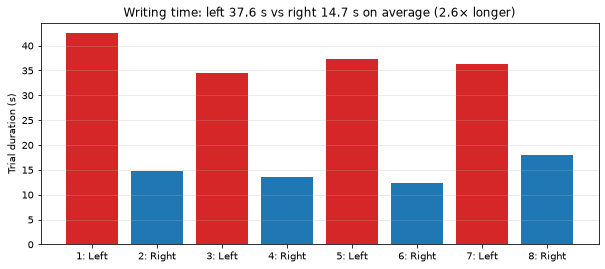

In [3]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(range(8), durations.duration_s, color=["C3" if h == "L" else "C0" for h in HANDS])
ax.set_xticks(range(8), TRIALS)
ax.set_ylabel("Trial duration (s)")
mean_l, mean_r = durations.query("hand == 'L'").duration_s.mean(), durations.query("hand == 'R'").duration_s.mean()
ax.set_title(f"Writing time: left {mean_l:.1f} s vs right {mean_r:.1f} s on average ({mean_l / mean_r:.1f}× longer)")
ax.grid(axis="y", alpha=0.3)
plt.show()

## 2. Data quality

Each trial is prepared for analysis (Fz, M1, M2 dropped; 1–100 Hz; 60 Hz notch; average
reference) and cut into 2 s windows. A window counts as clean on a channel if it swings less
than 150 µV.

**Why this plot:** it shows which channels and trials have enough clean EEG to trust before comparing hands.

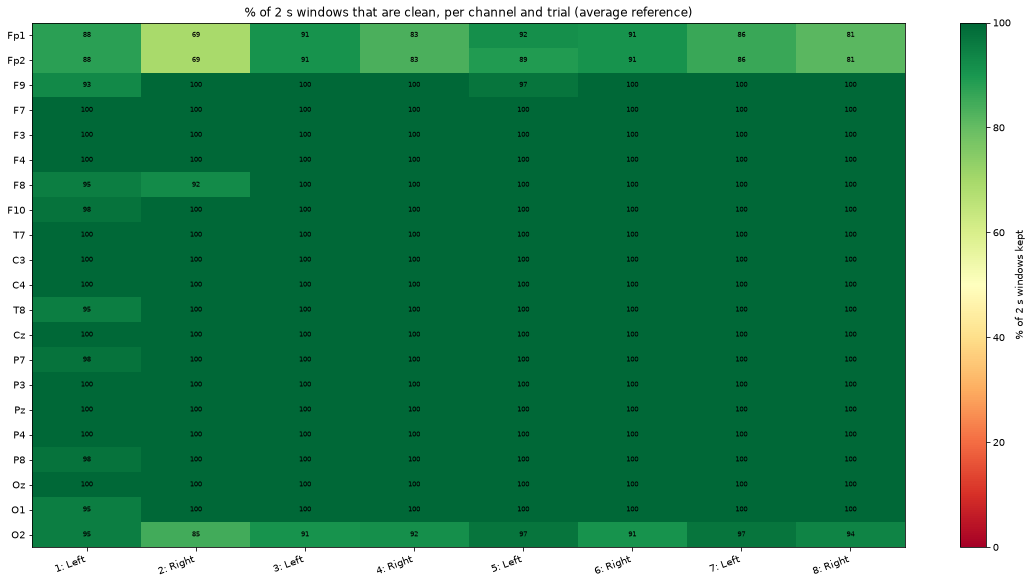

In [4]:
prepared = [prepare(seg, BAD_CHANNELS) for seg in segments]
spectra = [window_spectra(seg) for seg in prepared]
plot_quality(spectra, TRIALS, "% of 2 s windows that are clean, per channel and trial (average reference)")

## 3. Band plots: left-hand trials vs right-hand trials

The four trials of each hand are filtered separately and then joined end to end; dashed lines
mark where one trial ends and the next begins. Left-hand trials on the left, right-hand trials
on the right. Data is average-referenced (Fz, M1, M2 excluded).

In [5]:
def trial_marks(trials):
    edges = np.cumsum([t.times[-1] + 1 / t.info["sfreq"] for t in trials])[:-1]
    return [(e, "") for e in edges]

raw_trials = [seg.copy().drop_channels(BAD_CHANNELS) for seg in segments]
marks = [trial_marks(by_hand(prepared, "L")), trial_marks(by_hand(prepared, "R"))]
hand_labels = ["Left-hand trials (1, 3, 5, 7)", "Right-hand trials (2, 4, 6, 8)"]

### 3.1 Original data (no filtering, original reference)

**Why this plot:** check signal quality before any processing: drift, noisy channels, and movement or blink artifacts that filtering could hide or smear.

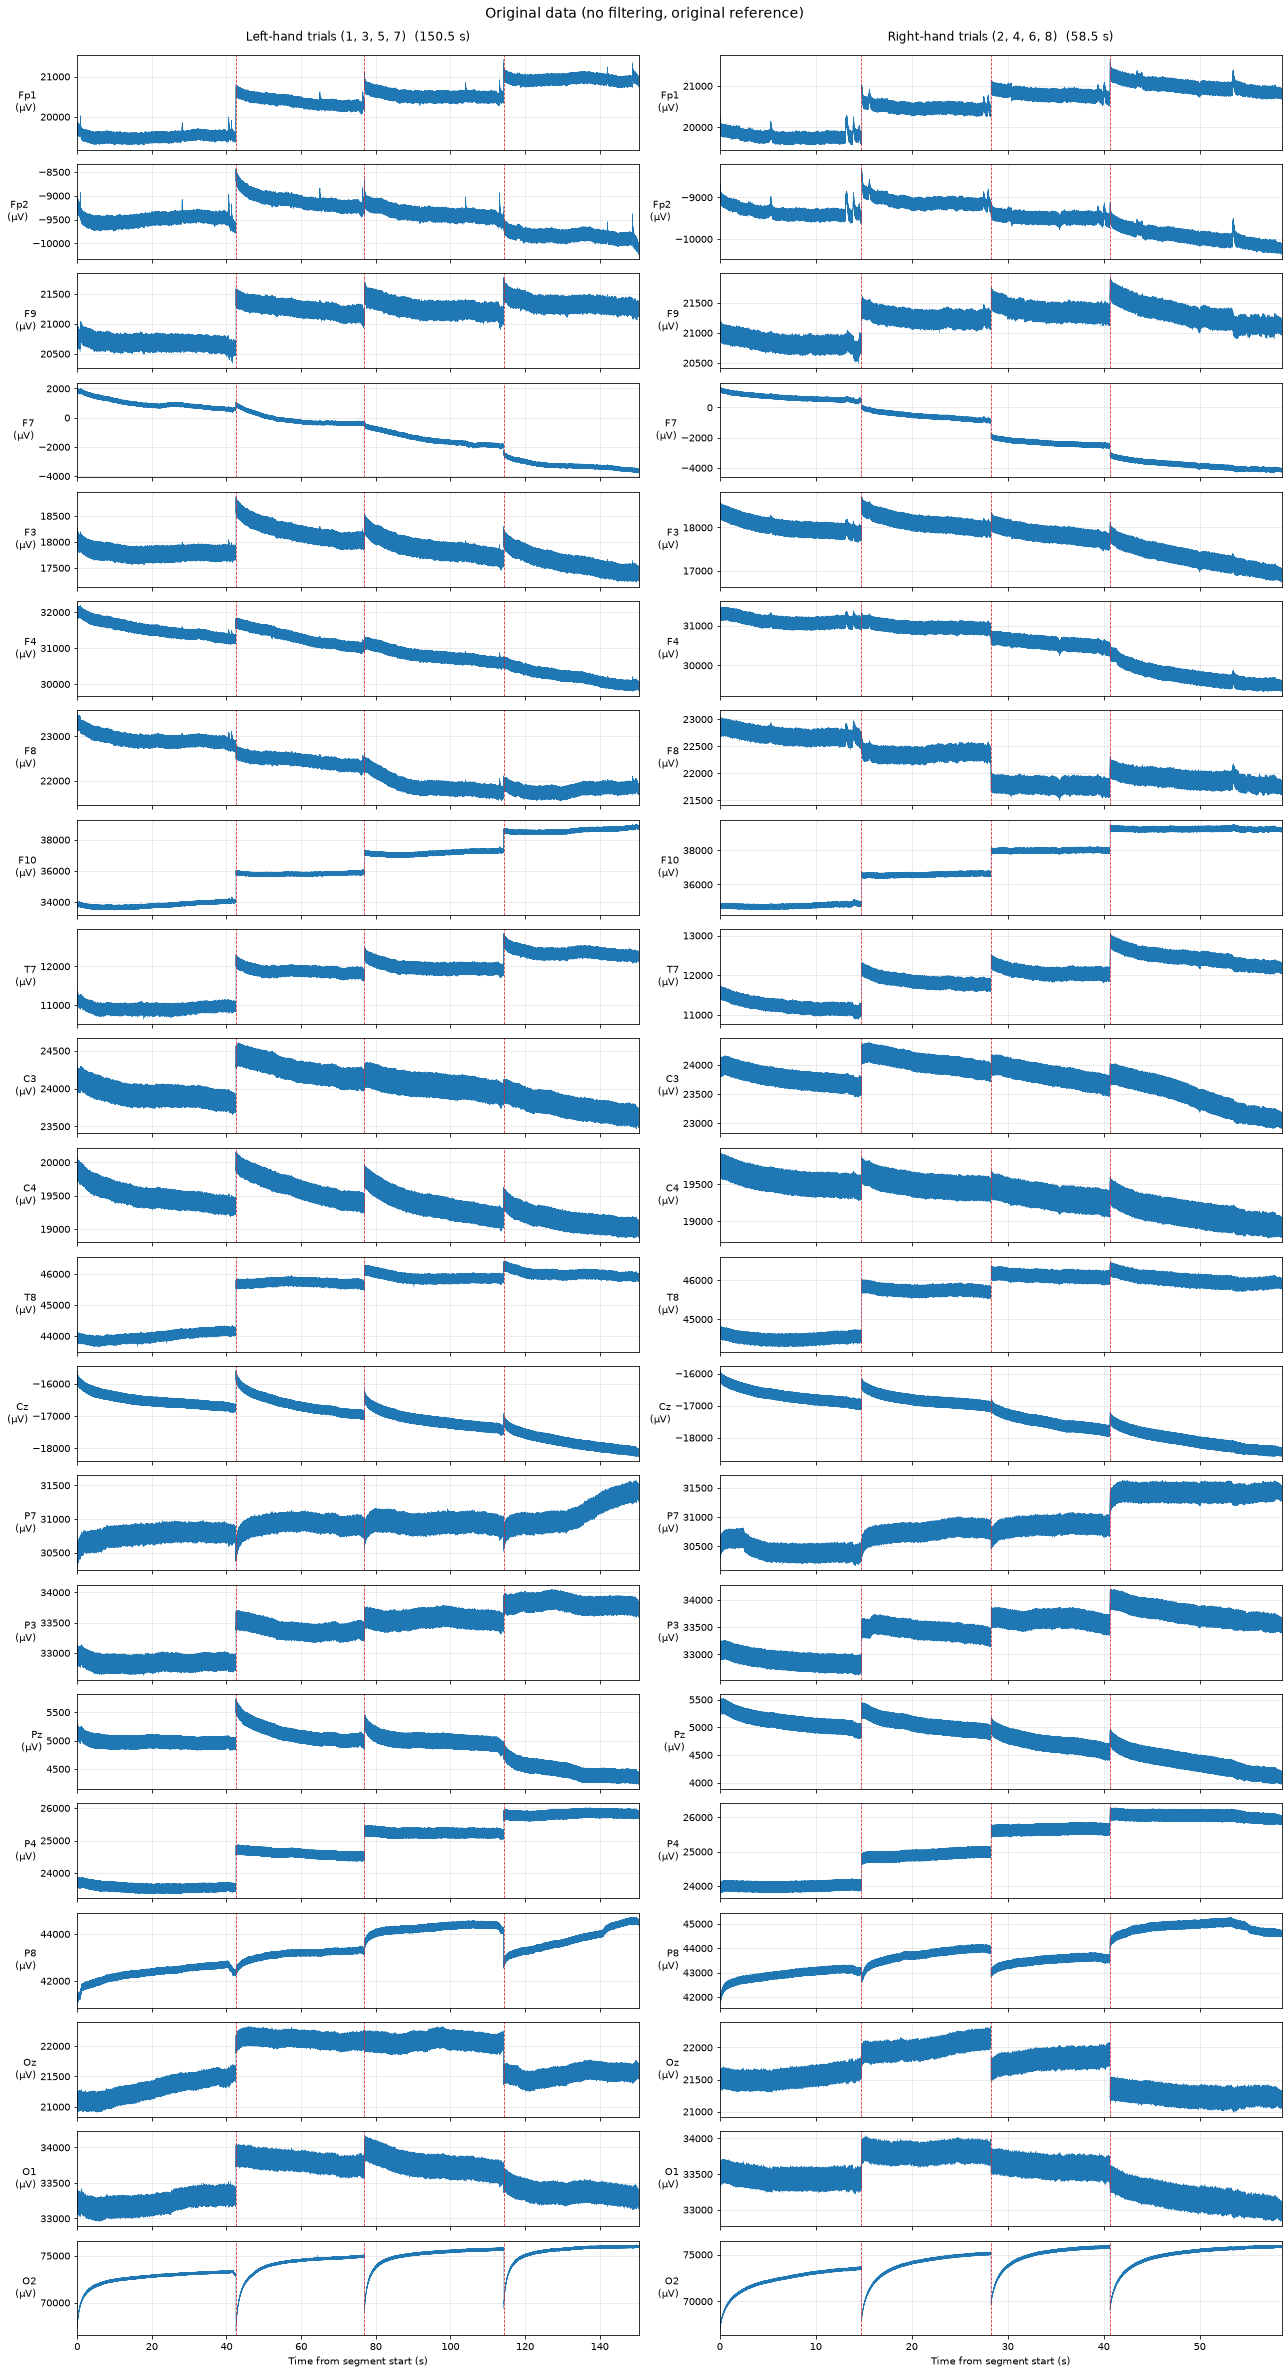

In [6]:
plot_segments([concat(by_hand(raw_trials, "L")), concat(by_hand(raw_trials, "R"))], hand_labels, "Original data (no filtering, original reference)", sharey_rows=False, marks=marks)

### 3.2 Theta band (4–8 Hz)

**Why this plot:** frontal theta (here F3/F4) rises with task difficulty and working memory load, so higher theta with the left hand would suggest it was more demanding.

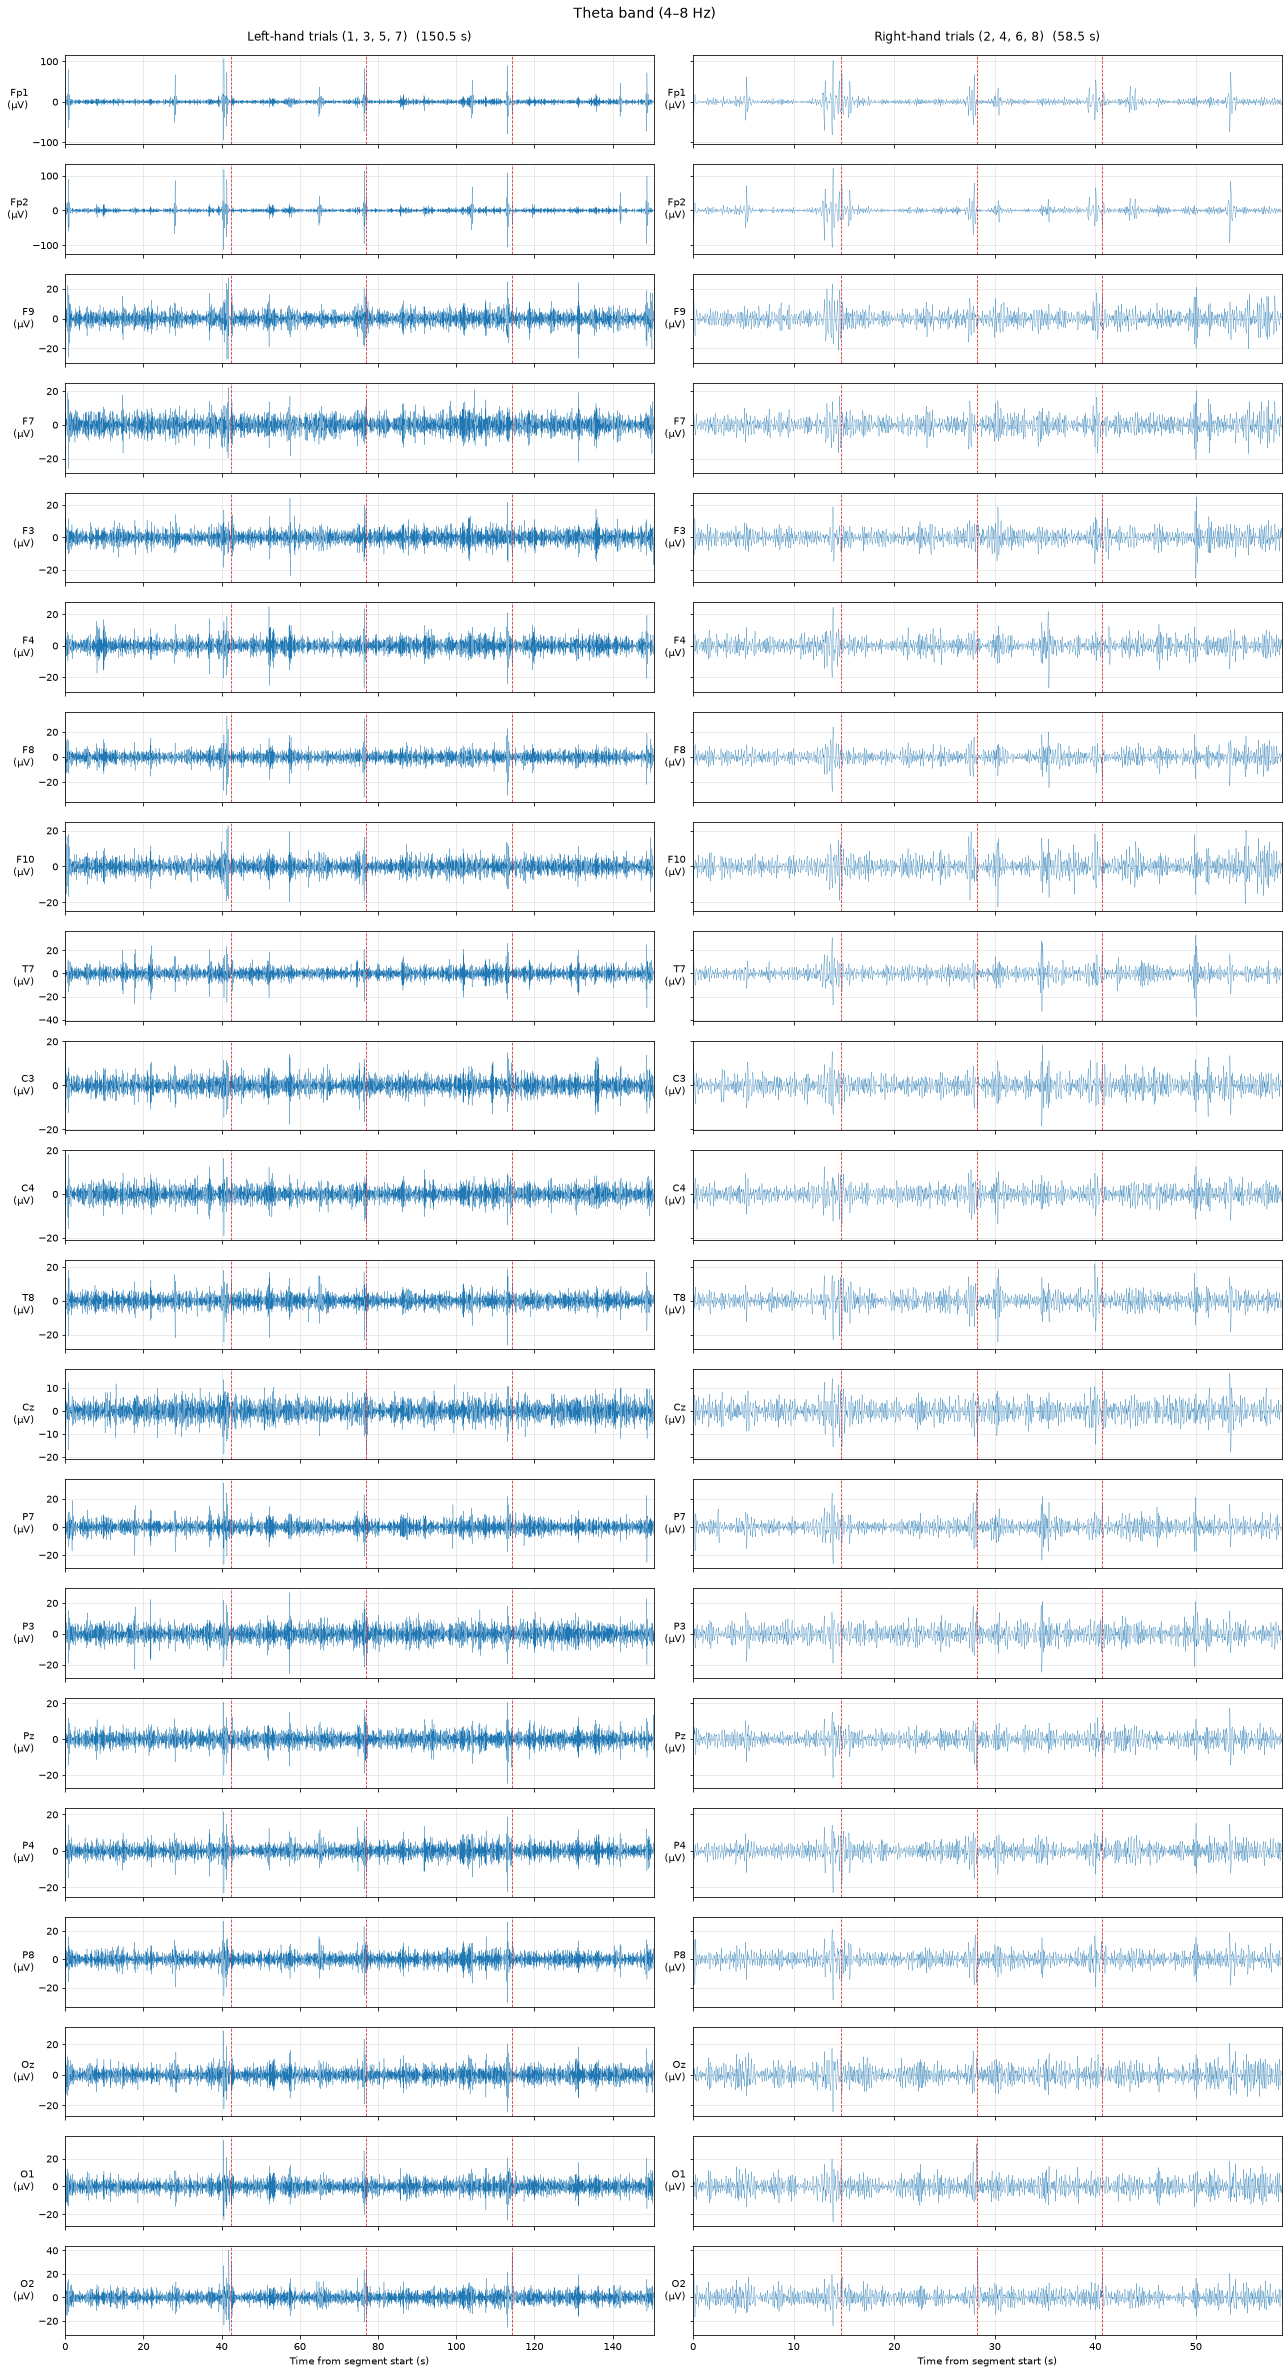

In [7]:
plot_segments([concat([band_filter(s, 4, 8) for s in by_hand(prepared, "L")]), concat([band_filter(s, 4, 8) for s in by_hand(prepared, "R")])], hand_labels, "Theta band (4–8 Hz)", marks=marks)

### 3.3 Alpha band (8–13 Hz)

**Why this plot:** parietal alpha weakens when the brain is engaged with a task, so lower alpha with the left hand would suggest it demanded more attention.

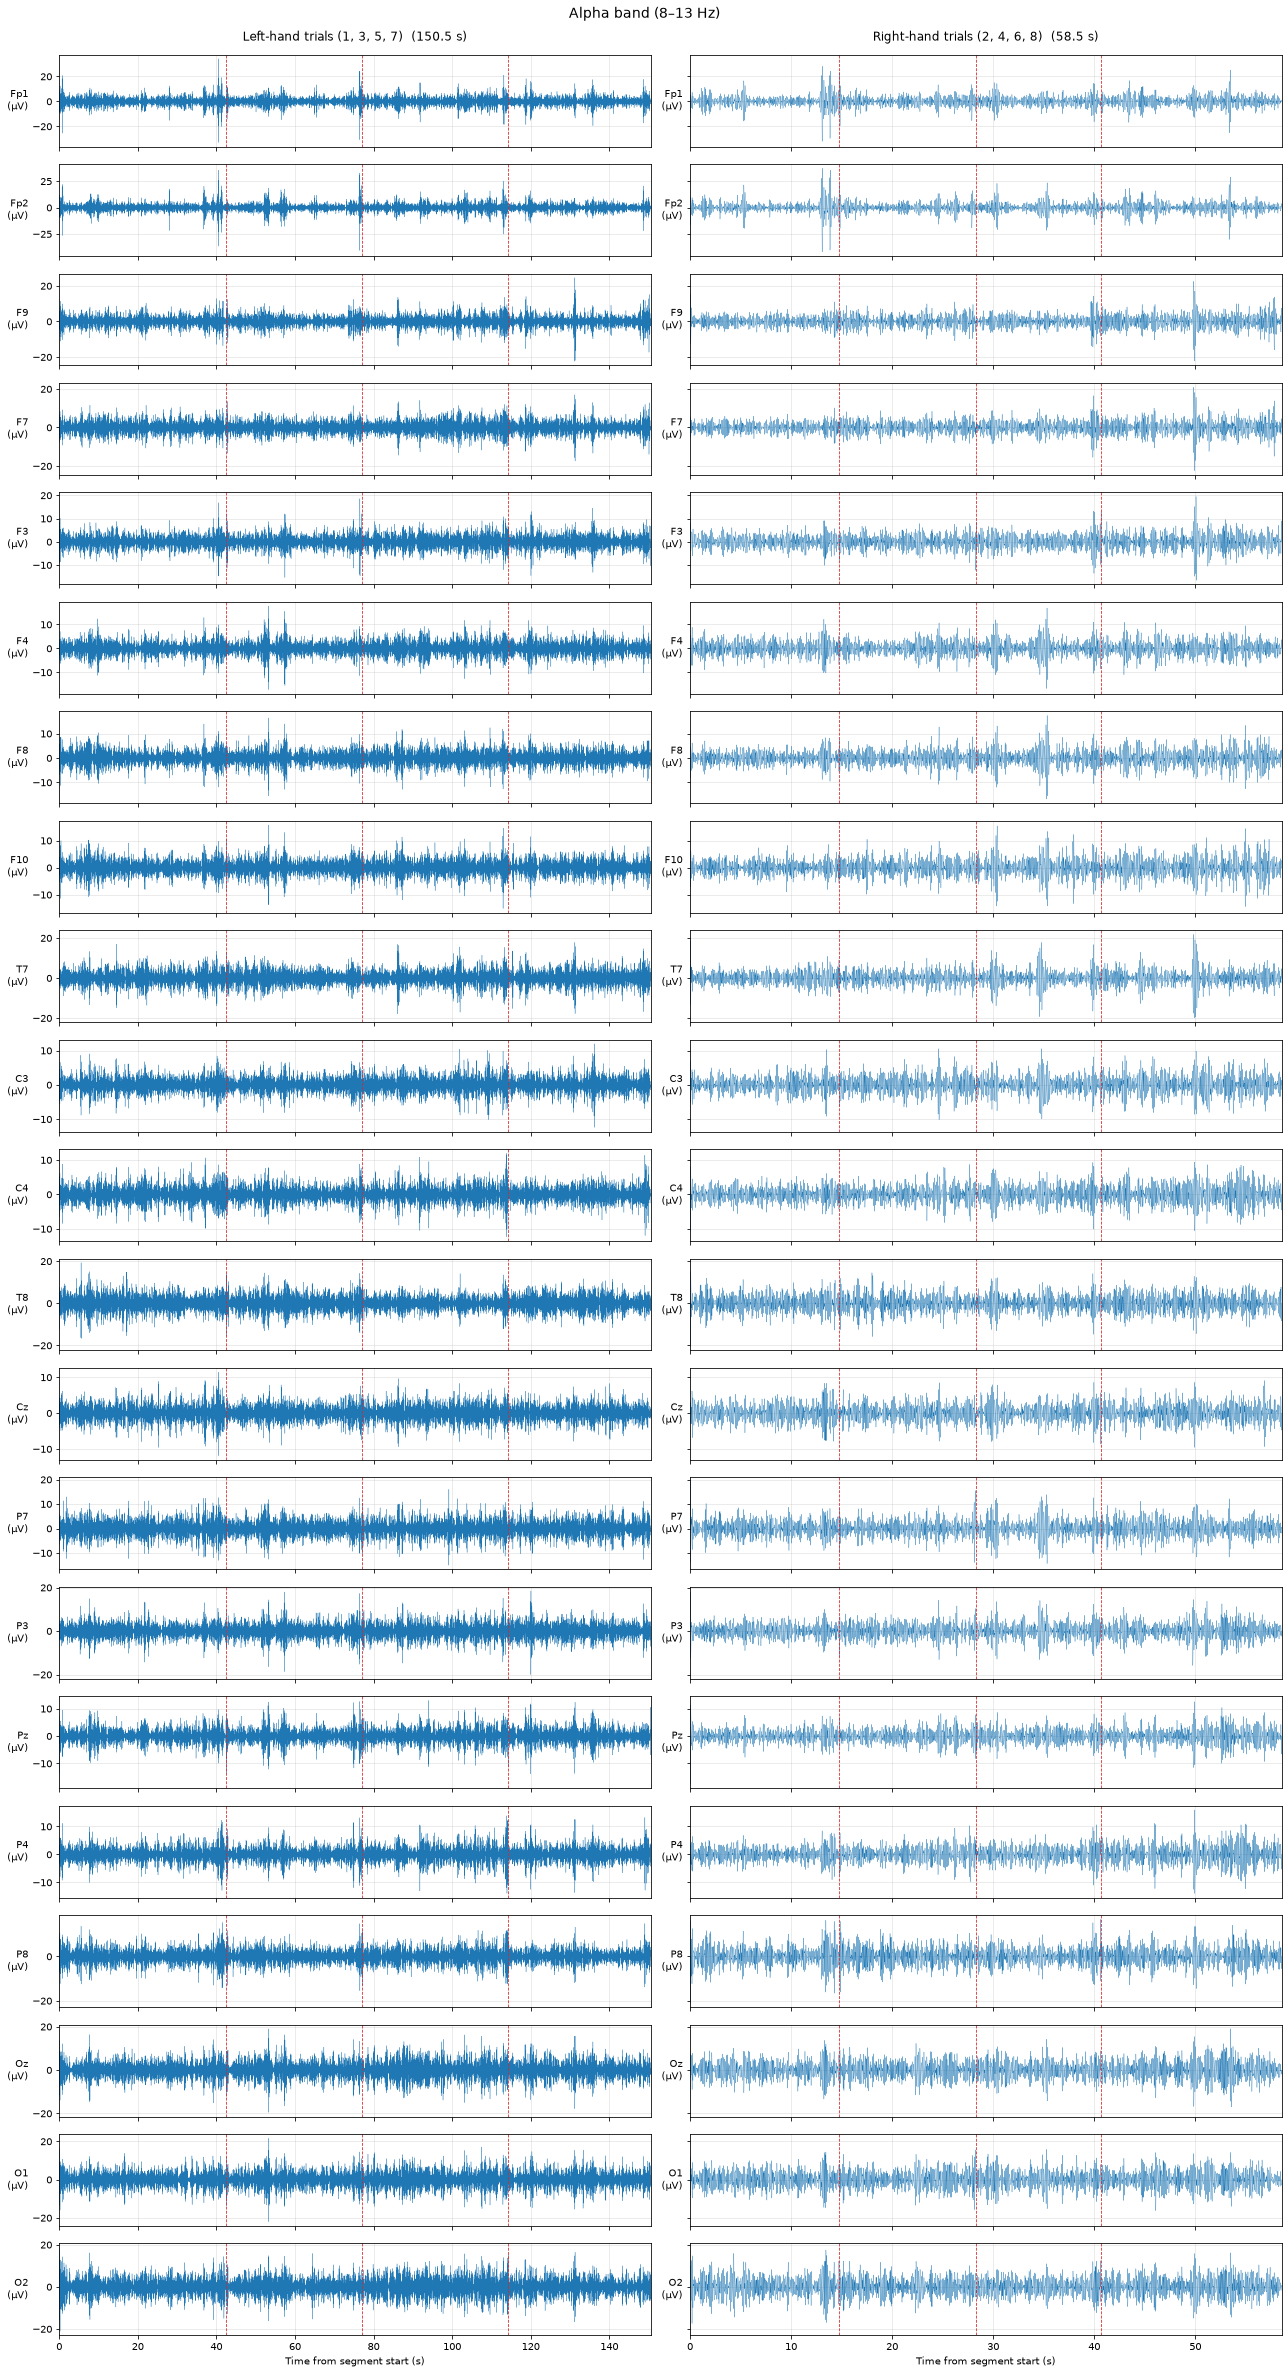

In [8]:
plot_segments([concat([band_filter(s, 8, 13) for s in by_hand(prepared, "L")]), concat([band_filter(s, 8, 13) for s in by_hand(prepared, "R")])], hand_labels, "Alpha band (8–13 Hz)", marks=marks)

### 3.4 Beta band (13–30 Hz)

**Why this plot:** beta mostly tracks movement and muscle activity (over C3/C4 it drops whenever the opposite hand moves), so it shows how differently the hands performed physically. It is a confound to watch, not a measure of effort.

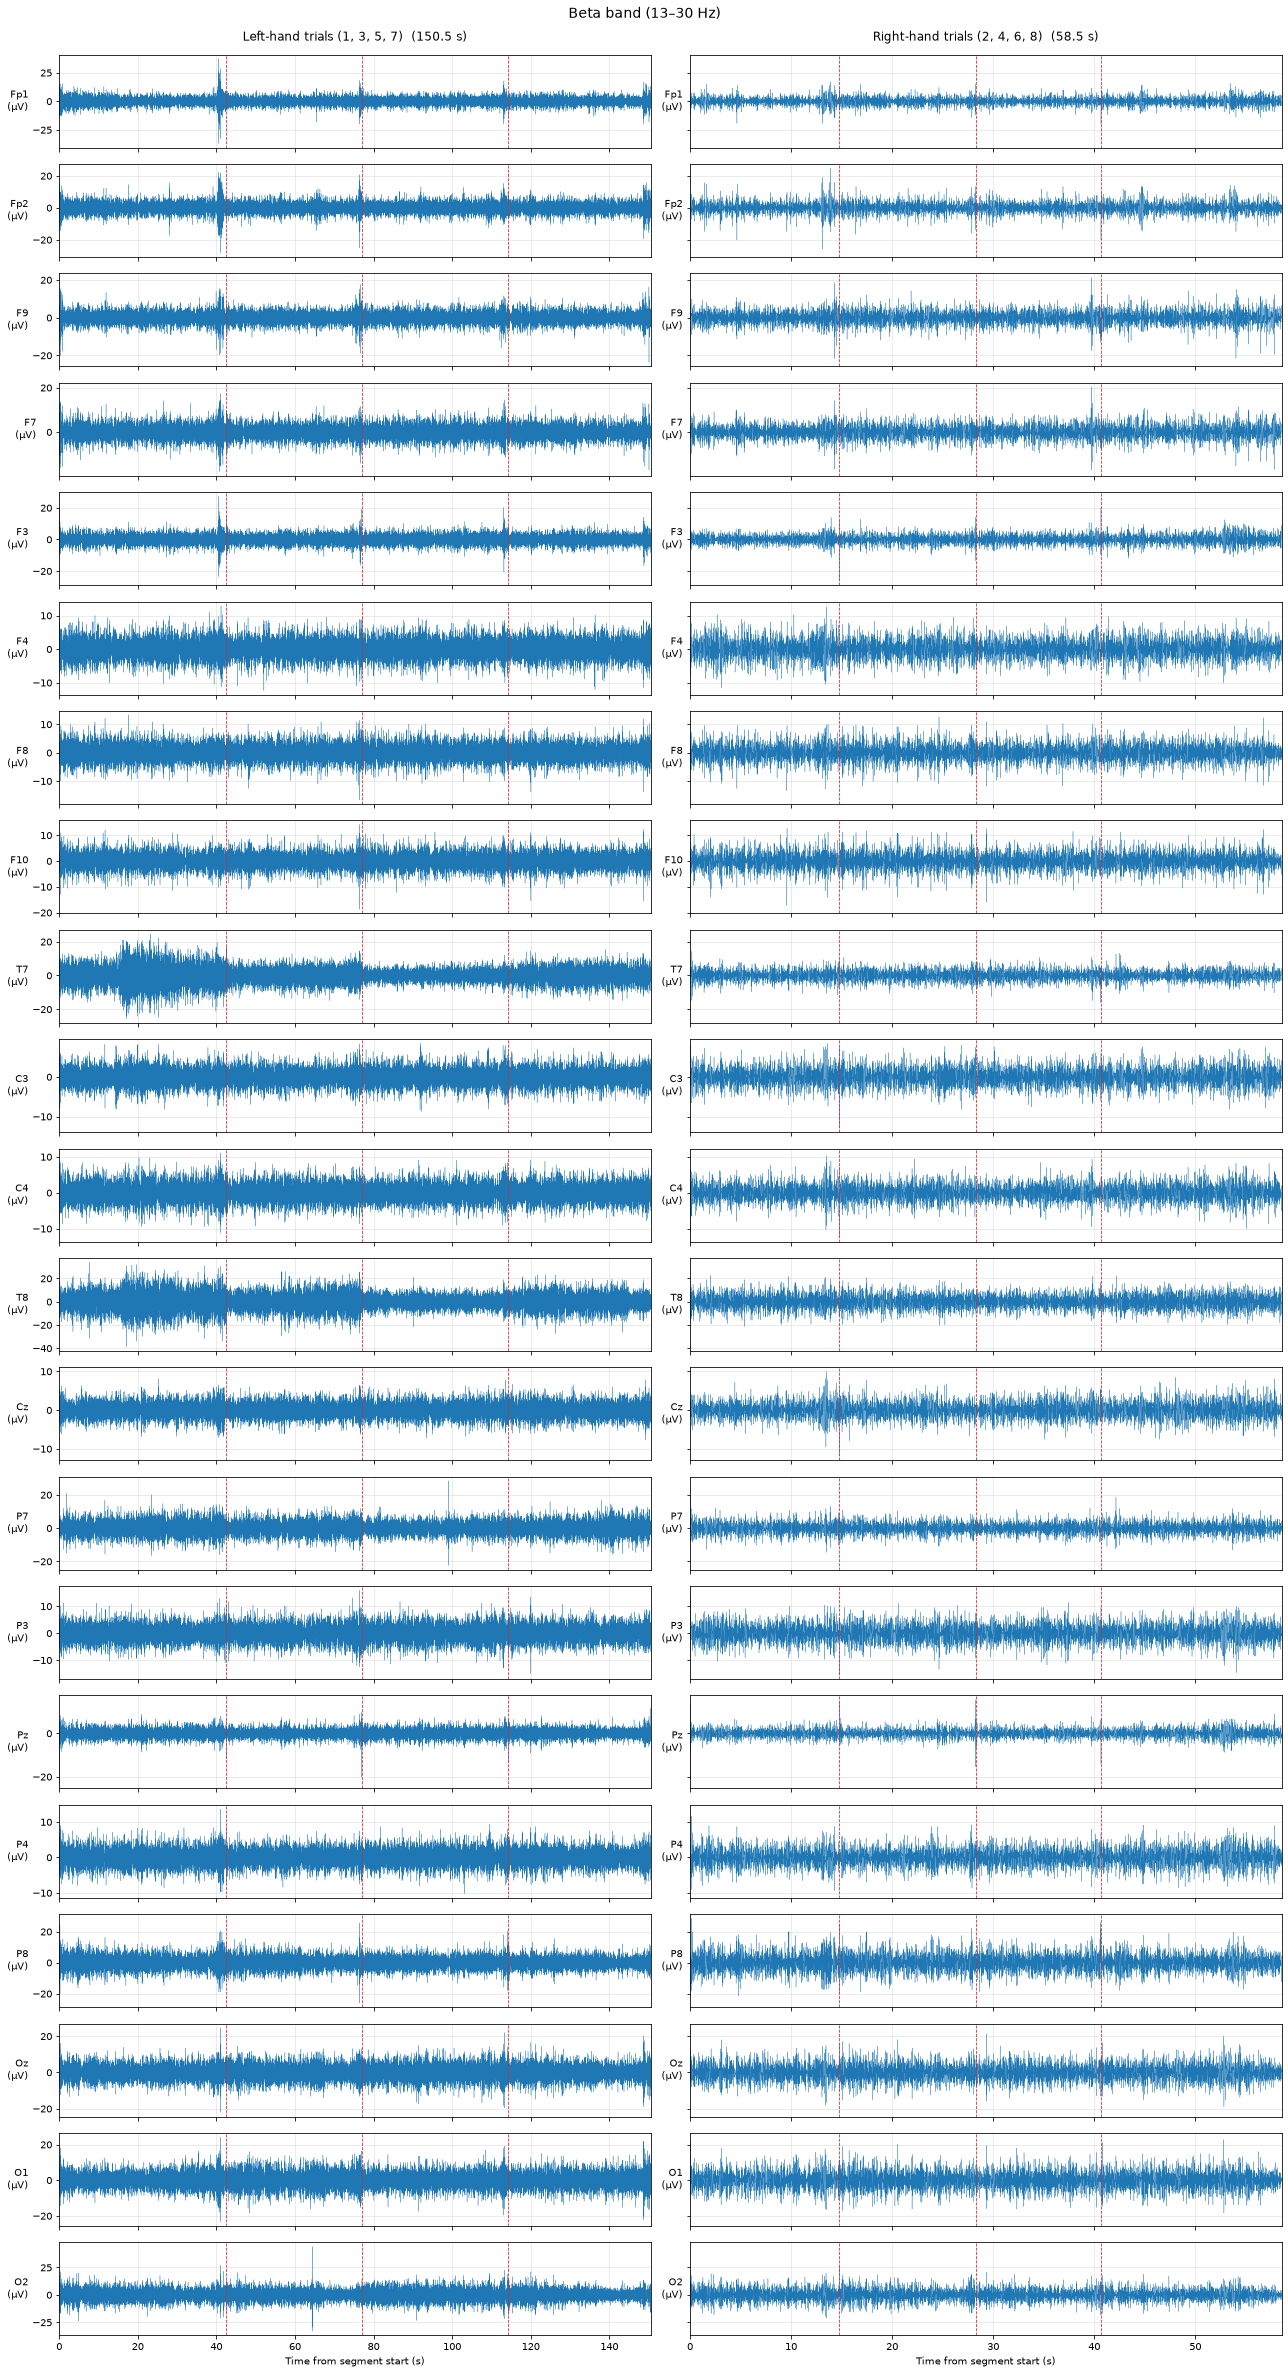

In [9]:
plot_segments([concat([band_filter(s, 13, 30) for s in by_hand(prepared, "L")]), concat([band_filter(s, 13, 30) for s in by_hand(prepared, "R")])], hand_labels, "Beta band (13–30 Hz)", marks=marks)

### 3.5 Gamma band (30–100 Hz)

**Why this plot:** gamma on the scalp is mostly muscle activity, so it shows how much muscle tension each hand produced. It is a confound to watch, not a measure of effort.

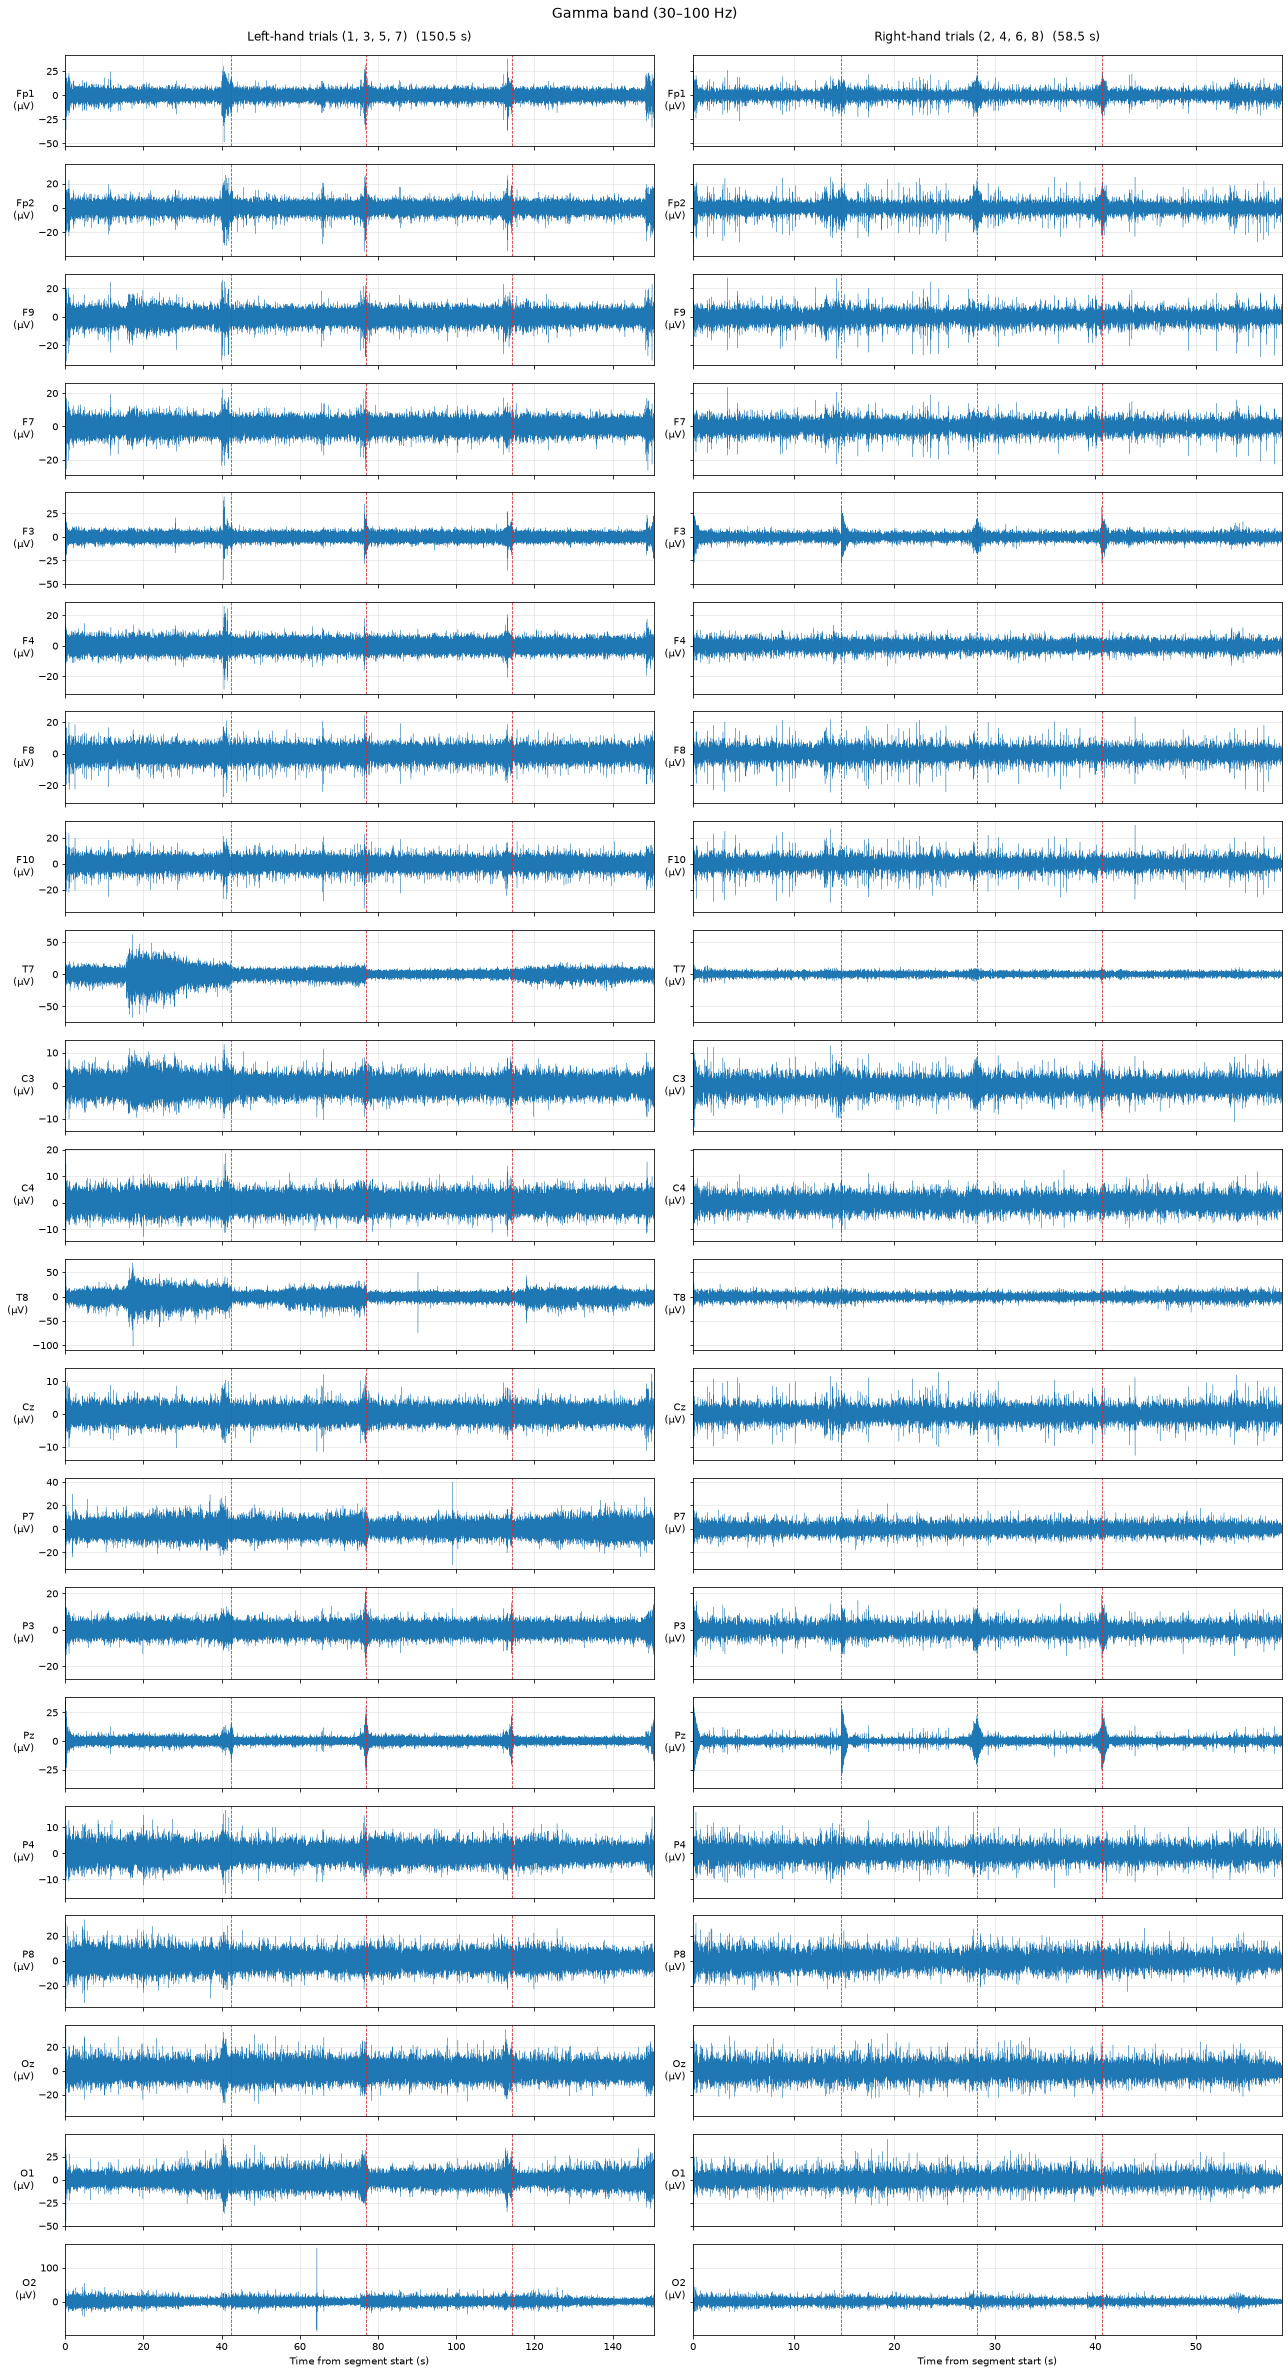

In [10]:
plot_segments([concat([band_filter(s, 30, 99) for s in by_hand(prepared, "L")]), concat([band_filter(s, 30, 99) for s in by_hand(prepared, "R")])], hand_labels, "Gamma band (30–100 Hz)", marks=marks)

## 4. Frequency decomposition (FFT)

Welch's method as before (2 s Hann windows, 50% overlap, 0.5 Hz resolution), with all
windows of the four trials of each hand pooled. Relative power is a band's share of 4–40 Hz.

**Why these plots:** the spectra show which frequencies carry the power for each hand; the
bars show across the head whether theta rises and alpha falls with the left hand.

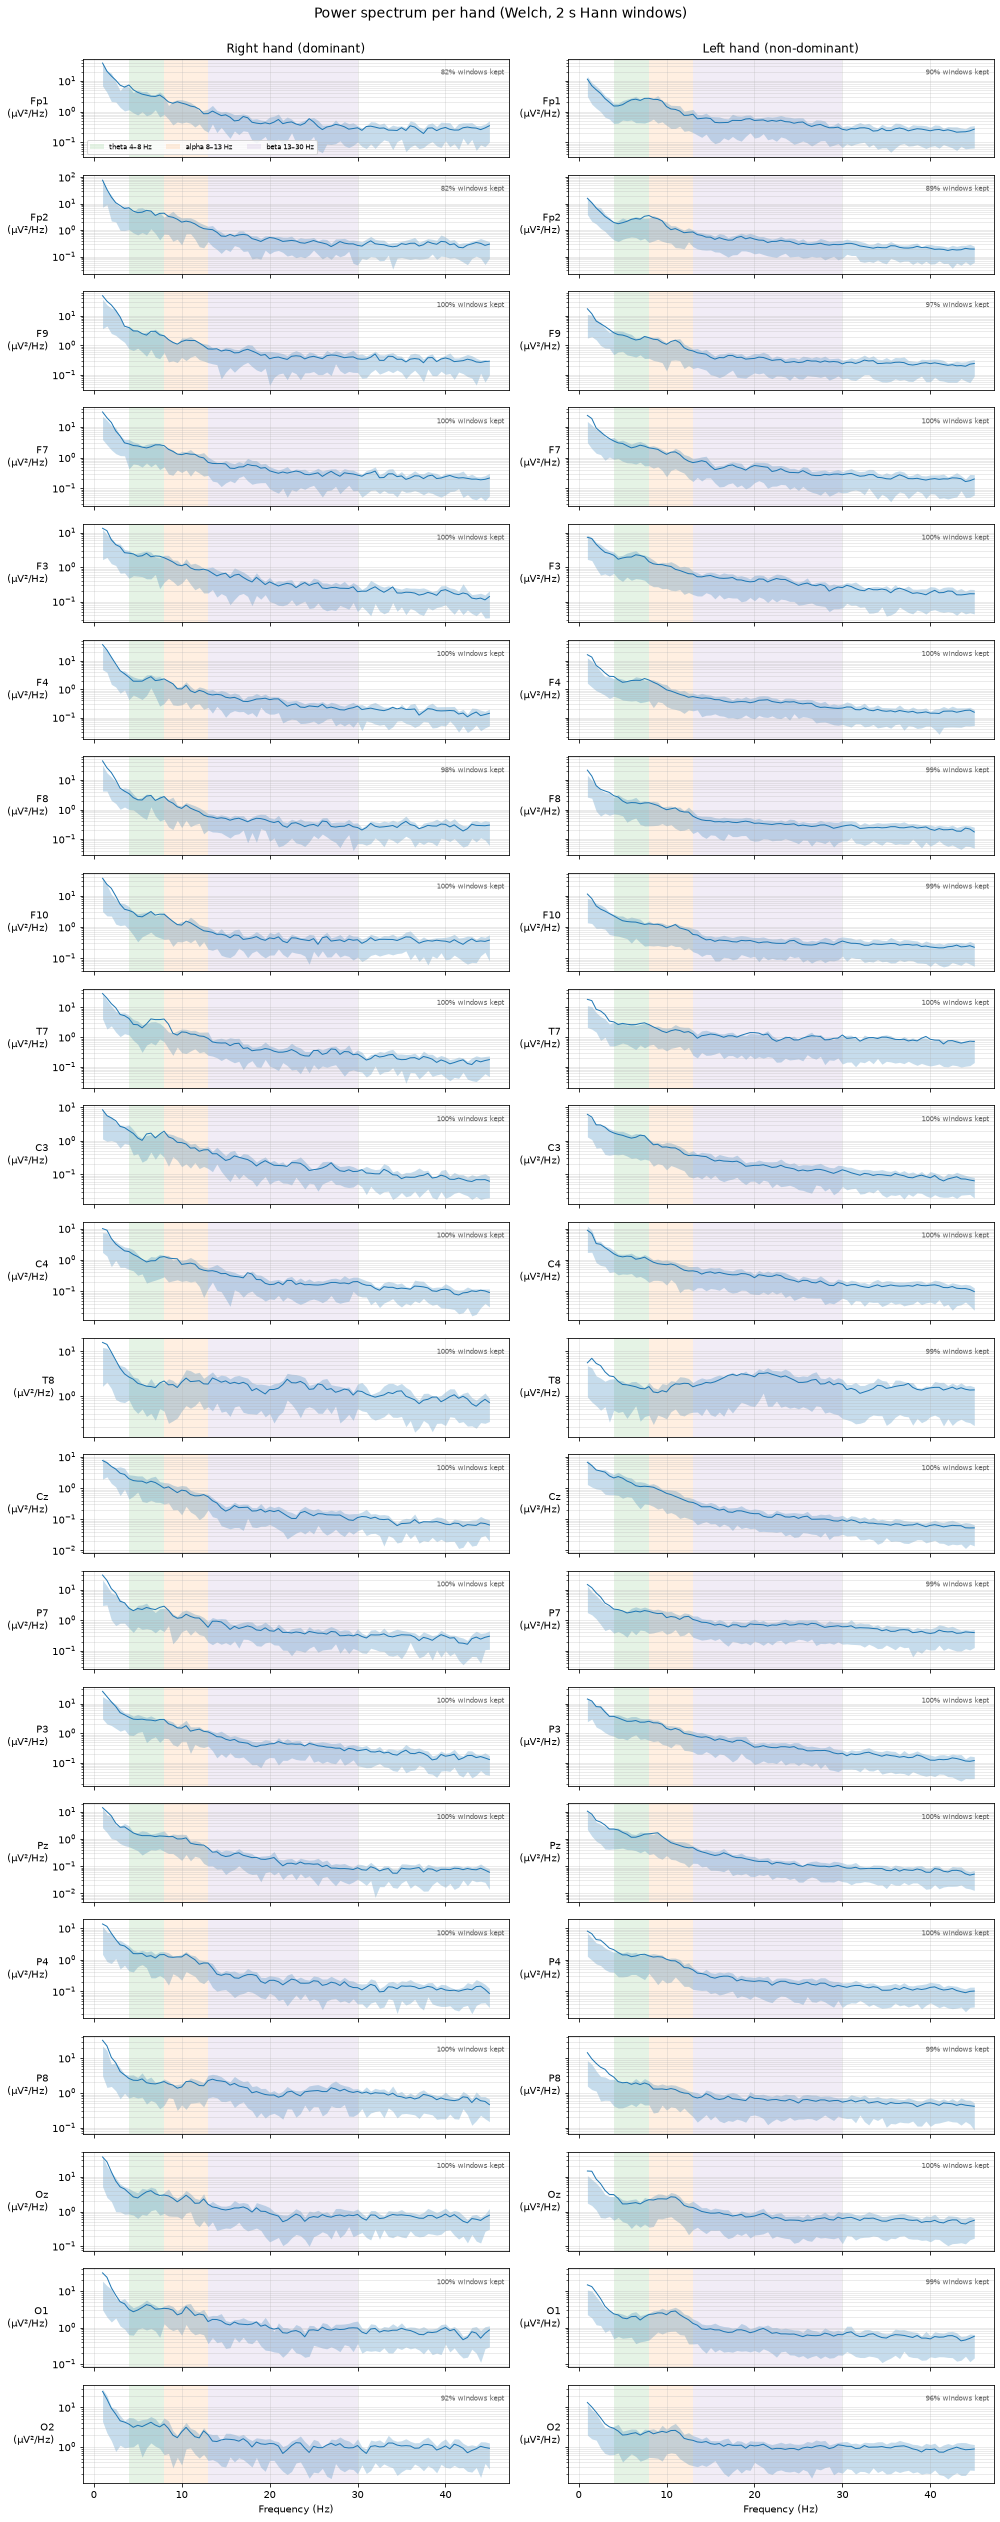

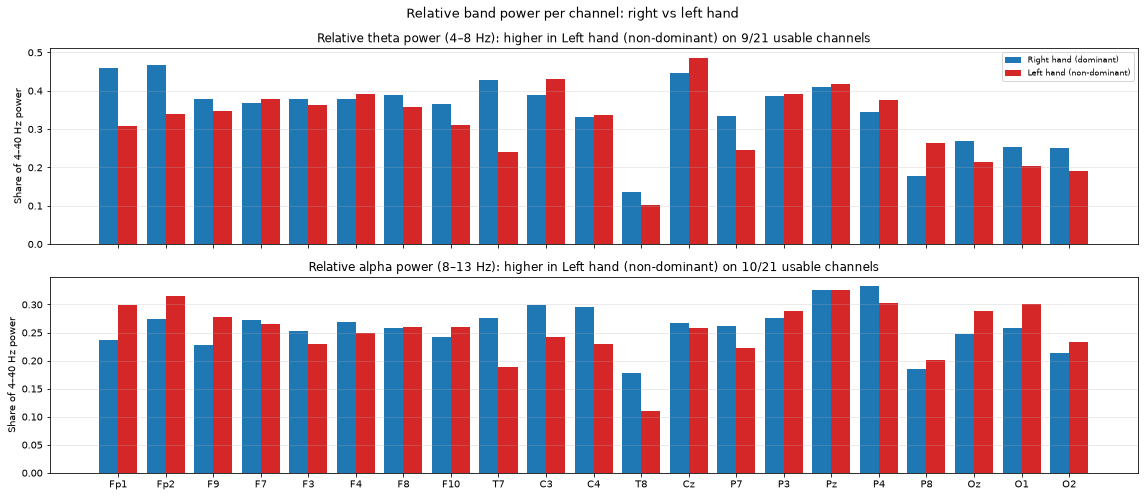

In [11]:
hand_spectra = [window_spectra(concat(by_hand(prepared, h))) for h in ("R", "L")]
plot_spectra(hand_spectra, GROUP_LABELS, "Power spectrum per hand (Welch, 2 s Hann windows)")
plot_relative_bars(hand_spectra, GROUP_LABELS, "Relative band power per channel: right vs left hand")

## 5. Cleaned analysis: ICA + theta/alpha above the 1/f background

As in Sessions 1–2: one ICA is fitted on all eight trials together and components confidently
(probability ≥ 0.7) classified by ICLabel as eye, muscle, heart, line noise or channel noise
are removed. FOOOF then fits the 1/f background, and theta (F3+F4) and alpha (Pz) are measured
as power **above** it, in dB.

ICA: 3 of 20 components removed: IC01 eye blink (0.97), IC02 eye blink (0.77), IC14 eye blink (0.90)


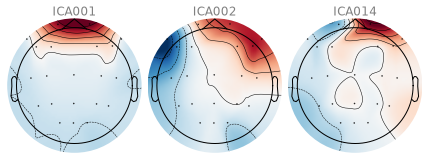

In [12]:
cleaned, ica_report, ica = ica_clean(prepared)
print(f"ICA: {int(ica_report.removed.sum())} of {len(ica_report)} components removed: "
      + ", ".join(f"{r.component} {r.label} ({r.probability:.2f})" for r in ica_report[ica_report.removed].itertuples()))
ica.plot_components(picks=ica.exclude, title="Components removed by ICLabel", show=False)
plt.show()

### 5.1 Trial by trial

Theta above 1/f at F3+F4, alpha above 1/f at Pz, and the 1/f exponent at F3+F4, for every trial
in recording order. Each left trial is paired with the right trial that follows it (block 1 =
trials 1–2, and so on).

**Why this plot:** with four separate trials per hand, it shows whether the left/right
difference repeats in every block or comes from one or two trials, and whether anything drifts
across the session.

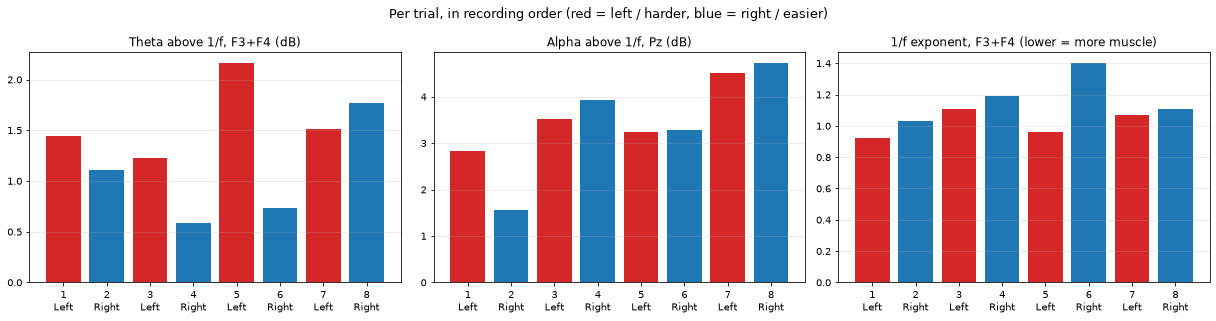

Blocks with higher theta for the left hand: 3 of 4; with lower alpha for the left hand: 3 of 4; with a flatter (lower) exponent for the left hand: 4 of 4


,trial,hand,duration_s,theta_F3+F4_dB,alpha_Pz_dB,exponent_F3+F4,windows_clean_%
0,1: Left,L,42.5,1.44,2.84,0.92,100
1,2: Right,R,14.8,1.11,1.57,1.03,100
2,3: Left,L,34.5,1.23,3.53,1.11,100
3,4: Right,R,13.5,0.59,3.92,1.19,100
4,5: Left,L,37.3,2.16,3.23,0.96,100
5,6: Right,R,12.4,0.73,3.28,1.40,100
6,7: Left,L,36.3,1.51,4.50,1.07,100
7,8: Right,R,17.9,1.77,4.72,1.11,100


,block,theta: left − right (dB),alpha: left − right (dB),exponent: left − right
0,1 (trials 1–2),0.33,1.27,-0.11
1,2 (trials 3–4),0.64,-0.39,-0.08
2,3 (trials 5–6),1.43,-0.05,-0.44
3,4 (trials 7–8),-0.26,-0.22,-0.04


In [13]:
rows = []
for trial, hand, seg in zip(TRIALS, HANDS, cleaned):
    sp = roi_spectrum(window_spectra(seg), THETA_CHANNELS)
    m = periodic_metrics(sp, THETA_SITE, ALPHA_SITE)
    rows.append({"trial": trial, "hand": hand, "duration_s": round(seg.times[-1], 1),
                 "theta_F3+F4_dB": m["theta_db"], "alpha_Pz_dB": m["alpha_db"],
                 "exponent_F3+F4": m[f"exponent_{THETA_SITE}"], "windows_clean_%": round(100 * sp[3][-1])})
per_trial = pd.DataFrame(rows).round(2)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, col, title in zip(axes, ["theta_F3+F4_dB", "alpha_Pz_dB", "exponent_F3+F4"],
                          ["Theta above 1/f, F3+F4 (dB)", "Alpha above 1/f, Pz (dB)", "1/f exponent, F3+F4 (lower = more muscle)"]):
    ax.bar(range(8), per_trial[col], color=["C3" if h == "L" else "C0" for h in HANDS])
    ax.set_xticks(range(8), [t.replace(": ", "\n") for t in TRIALS])
    ax.set_title(title)
    ax.axhline(0, color="k", lw=0.6)
    ax.grid(axis="y", alpha=0.3)
fig.suptitle("Per trial, in recording order (red = left / harder, blue = right / easier)", fontsize=13)
fig.tight_layout()
plt.show()

blocks = pd.DataFrame({
    "block": [f"{b + 1} (trials {2 * b + 1}–{2 * b + 2})" for b in range(4)],
    "theta: left − right (dB)": [per_trial["theta_F3+F4_dB"][2 * b] - per_trial["theta_F3+F4_dB"][2 * b + 1] for b in range(4)],
    "alpha: left − right (dB)": [per_trial["alpha_Pz_dB"][2 * b] - per_trial["alpha_Pz_dB"][2 * b + 1] for b in range(4)],
    "exponent: left − right": [per_trial["exponent_F3+F4"][2 * b] - per_trial["exponent_F3+F4"][2 * b + 1] for b in range(4)],
}).round(2)
print(f"Blocks with higher theta for the left hand: {(blocks['theta: left − right (dB)'] > 0).sum()} of 4; "
      f"with lower alpha for the left hand: {(blocks['alpha: left − right (dB)'] < 0).sum()} of 4; "
      f"with a flatter (lower) exponent for the left hand: {(blocks['exponent: left − right'] < 0).sum()} of 4")
display(per_trial)
display(blocks)

### 5.2 Both hands pooled

**Why these plots:** pooling the four trials per hand gives smoother spectra, so the 1/f fits
and per-channel values are more stable than in single 12–17 s right-hand trials.

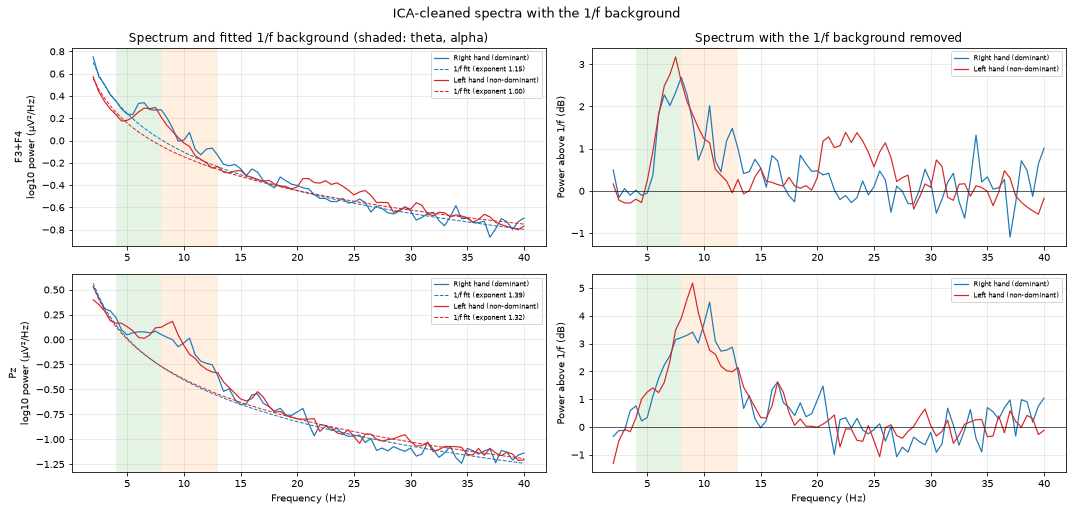

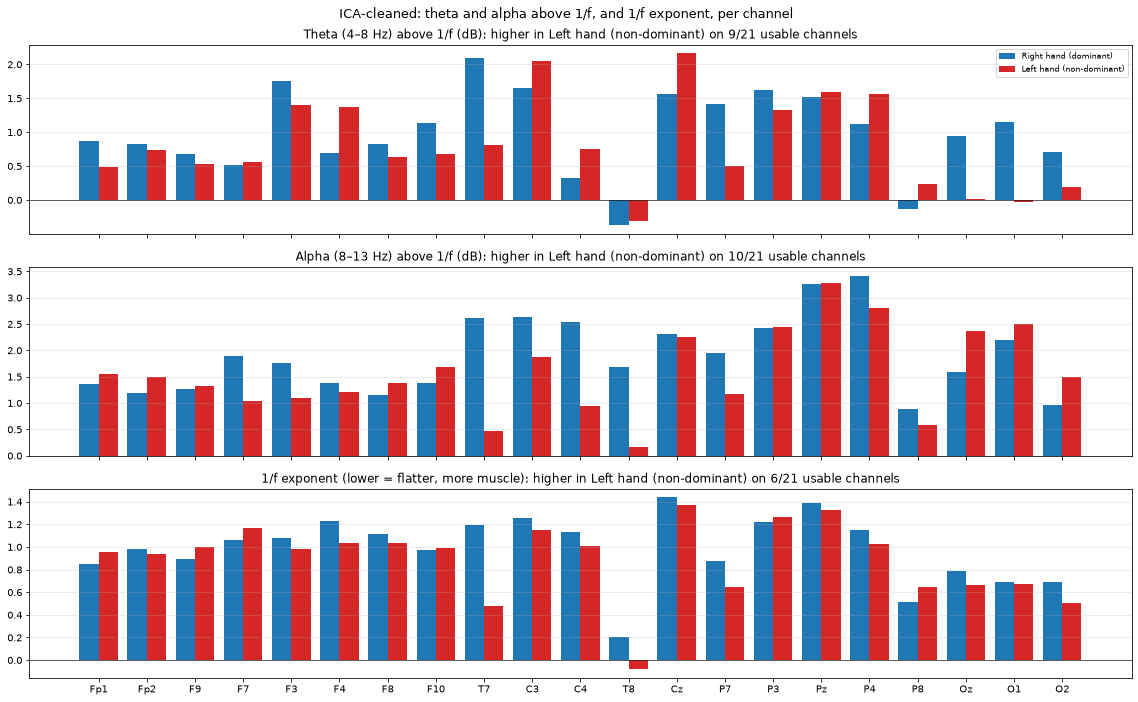

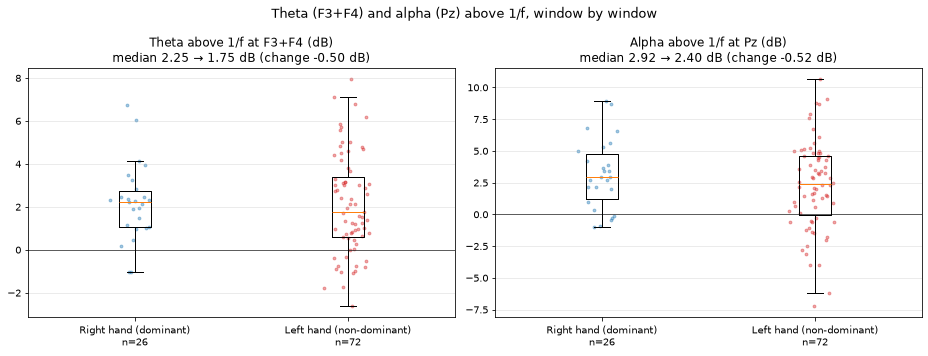

,Right hand (dominant),Left hand (non-dominant),change_dB,descriptive_p_higher,descriptive_p_lower,n
measure,,,,,,
Theta above 1/f at F3+F4 (dB),2.25,1.75,-0.50,0.65,0.35,26 / 72
Alpha above 1/f at Pz (dB),2.92,2.40,-0.52,0.85,0.15,26 / 72


In [14]:
clean_spectra = [roi_spectrum(window_spectra(concat(by_hand(cleaned, h))), THETA_CHANNELS) for h in ("R", "L")]
plot_fooof_fits(clean_spectra, GROUP_LABELS, "ICA-cleaned spectra with the 1/f background", channels=(THETA_SITE, ALPHA_SITE))
plot_periodic_bars([(p[:, :-1], f, c[:-1], k[:-1]) for p, f, c, k in clean_spectra], GROUP_LABELS,
                   "ICA-cleaned: theta and alpha above 1/f, and 1/f exponent, per channel")
clean_nonoverlap = [roi_spectrum(window_spectra(concat(by_hand(cleaned, h)), overlap=0.0), THETA_CHANNELS) for h in ("R", "L")]
periodic_workload_comparison(clean_nonoverlap, GROUP_LABELS, "Theta (F3+F4) and alpha (Pz) above 1/f, window by window",
                             theta_ch=THETA_SITE, alpha_ch=ALPHA_SITE, min_windows=10)

### 5.3 Theta under three definitions

**Theta power** at a channel is the total power between 4 and 8 Hz: the power spectral density
P(f) (Welch: 2 s Hann windows, 50% overlap, averaged over the clean windows) integrated over
4–8 Hz, in µV², reported as 10·log₁₀(θ / 1 µV²) dB. For a region such as F3+F4 the PSD is averaged
over its channels first. It is shown next to the two derived measures used elsewhere in this
notebook: **relative theta** (θ ÷ 4–40 Hz power) and **theta above 1/f** (the 4–8 Hz peak above the
fitted background). If all three move together, the change is in theta itself; if they disagree,
part of the change is in the rest of the spectrum (other bands, or the 1/f background).

**Caveat:** every trial is followed by an impedance check, so electrode contact can drift between
trials, which shifts absolute power. Each left trial is compared with the right trial right after
it, so slow drift affects both hands about equally, but absolute power is still a check, not the main result.

**Why this plot:** it shows, trial by trial, whether theta power itself is higher for the left hand,
and whether the three definitions agree on the per-block differences.

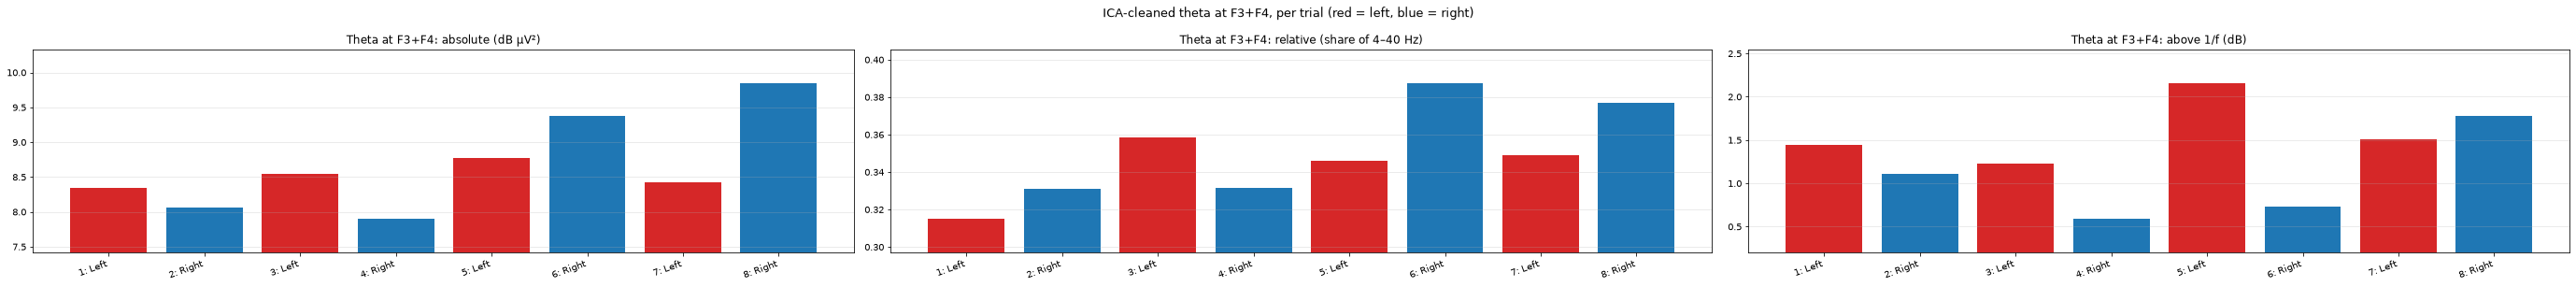

,absolute (dB µV²),relative (share of 4–40 Hz),above 1/f (dB)
1: Left,8.345,0.315,1.439
2: Right,8.066,0.331,1.110
3: Left,8.543,0.359,1.227
4: Right,7.903,0.331,0.592
5: Left,8.767,0.346,2.157
6: Right,9.381,0.387,0.730
7: Left,8.418,0.349,1.510
8: Right,9.847,0.377,1.774


,absolute (dB µV²),relative (share of 4–40 Hz),above 1/f (dB)
block 1: left − right,0.278,-0.016,0.328
block 2: left − right,0.640,0.027,0.635
block 3: left − right,-0.614,-0.041,1.427
block 4: left − right,-1.429,-0.028,-0.263
blocks with left > right,2.000,1.000,3.000


,absolute (dB µV²),relative (share of 4–40 Hz),above 1/f (dB)
Right hand (dominant),8.956,0.359,1.086
Left hand (non-dominant),8.457,0.338,1.364


In [15]:
from processing.analysis import plot_theta_definitions, theta_definitions

trial_spectra = [roi_spectrum(window_spectra(seg), THETA_CHANNELS) for seg in cleaned]
theta_trials = plot_theta_definitions(trial_spectra, TRIALS, THETA_SITE, "ICA-cleaned theta at F3+F4, per trial (red = left, blue = right)",
                                      colors=["C3" if h == "L" else "C0" for h in HANDS])
theta_blocks = pd.DataFrame({col: [theta_trials[col].iloc[2 * b] - theta_trials[col].iloc[2 * b + 1] for b in range(4)]
                             for col in theta_trials.columns},
                            index=[f"block {b + 1}: left − right" for b in range(4)]).round(3)
theta_blocks.loc["blocks with left > right"] = (theta_blocks > 0).sum().astype(int)
theta_pooled = pd.DataFrame([theta_definitions(s, THETA_SITE) for s in clean_spectra], index=GROUP_LABELS).round(3)
display(theta_trials.round(3))
display(theta_blocks)
display(theta_pooled)

**What 5.3 shows: theta power itself is not higher for the left hand.**

| Theta at F3+F4 | Absolute power | Relative (share of 4–40 Hz) | Above 1/f |
|---|---|---|---|
| Blocks with left > right | **2 of 4** (+0.28, +0.64, −0.61, −1.43 dB) | **1 of 4** | **3 of 4** (+0.33, +0.64, +1.43, −0.26 dB) |
| Pooled: right → left | 8.96 → 8.46 dB µV² (**−0.50 dB**) | 0.359 → 0.338 | +1.09 → +1.36 dB (+0.28 dB) |

- Only the measure that removes the 1/f background leans towards the left hand, and only weakly. The
  left hand's spectrum is flatter in every block (more muscle activity), which lowers the fitted
  background and lifts the theta peak above it without more theta power.
- **The above-1/f result depends on how F3 and F4 are combined:** fitting FOOOF to each channel
  separately and averaging gives left − right of −0.08, +0.29, +1.14, −0.25 dB, i.e. **2 of 4 blocks**,
  instead of 3 of 4 from the averaged spectrum.
- **Right-hand theta power rises across the session** (8.07, 7.90, 9.38, 9.85 dB µV² in trials 2, 4, 6, 8)
  while left-hand theta stays flat (8.3–8.8 dB). That's why blocks 3 and 4 go the "wrong" way on absolute
  power: a time trend in one hand, not a hand difference.

## 6. Results: does the data support the hypothesis?

**Weakly at best. The left hand was clearly harder to use (writing took 2.6× longer), but the
EEG workload markers barely differ: the theta peak above 1/f is slightly higher for the left hand in
2–3 of 4 blocks while theta power itself isn't (section 5.3), alpha doesn't change, and the clearest
left/right difference is extra muscle activity.**

| Measure (ICA-cleaned, above 1/f) | Right hand (dominant) | Left hand (non-dominant) | Consistent? |
|---|---|---|---|
| Writing time per trial | 14.6 s | 37.6 s | **Yes**: left slower in all 4 blocks |
| Theta above 1/f at F3+F4, per trial | | | Left higher in **3 of 4 blocks** (+0.3, +0.6, +1.4, −0.3 dB; mean +0.5 dB); 2 of 4 if F3 and F4 are fitted separately |
| Theta *power* at F3+F4 (absolute), per trial | | | Left higher in only **2 of 4 blocks**; pooled −0.5 dB (section 5.3) |
| Theta at F3+F4, pooled averaged spectrum | +1.09 dB | +1.36 dB | +0.3 dB |
| Theta at F3+F4, pooled window median | +2.25 dB | +1.75 dB | **Opposite direction** (−0.5 dB, descriptive p = 0.35) |
| Alpha at Pz, per trial | | | Left lower in 3 of 4 blocks, but only by 0.05–0.4 dB; block 1 is +1.3 dB the other way |
| Alpha at Pz, pooled averaged spectrum | +3.26 dB | +3.27 dB | No difference |
| 1/f exponent at F3+F4 | 1.15 | 1.00 | **Flatter for the left hand in 4 of 4 blocks** (more muscle activity) |

How to read this:
- **The left hand was harder to use, but not clearly more mentally demanding in the EEG.**
  Writing time is the most solid result here. The theta difference is small, and it changes sign
  depending on whether you average the spectra or take the median of windows, so it's not robust.
- **The consistent difference is muscle activity:** a flatter spectrum for the left hand in every
  block, as in Session 1. Gripping and controlling the pen with the non-dominant hand takes more
  muscle tension, which no cleaning fully removes.
- **Alpha at Pz rises across the session for both hands** (about 1.6–2.8 dB in trials 1–2 vs 4.5–4.7 dB
  in trials 7–8). That's a time trend (practice, relaxation or fatigue), not a hand difference, and the
  alternating design is what lets it be seen separately from the hand effect.
- **Fz couldn't be used** (saturated electrode), so frontal theta comes from F3+F4, which sit
  slightly away from where frontal-midline theta is strongest.
- **Right-hand trials are short (12–18 s),** so their per-trial values rest on only 11–17 windows each.

**Compared with Sessions 1–2:** Session 1 showed the clearest effect (Fz theta up, Pz alpha down);
Session 2's writing and this session show little. Each session is a single person and short
trials, so these differences can't be separated from noise without more recordings.